# 09 · Explaining every decision

The second judging criterion was explainability: for any request, the system must be able to say
*why* it was accepted or rejected. Every decision is explained on two levels:

1. **The economics** (from the policy): show-up probability, expected value of the stay, the bid
   price of the nights, and which check decided (rate below the bid price, nights already full,
   capacity).
2. **The cancellation forecast** (from the model): the inputs that moved the probability most.

## How a stack of three models can be explained exactly

The final logit is a weighted sum of the members' logits:

`logit(p) = b + w_LR·z_LR + w_LGB·z_LGB + w_CB·z_CB`

and each member's logit splits additively over the input columns: logistic regression by
construction (coefficient × value), LightGBM and CatBoost through TreeSHAP (exact for trees).
Multiplying each member's contributions by
its stack weight and summing gives **per-column contributions that add up exactly to the final
logit** (`src/explain.py`, `decompose`).

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parent))
from src.simulator import load_train, build_holdout
from src.explain import decompose, label, outcome
from src import plotting as P

P.setup()
pd.set_option("display.width", 180); pd.set_option("display.max_colwidth", 200)
R = Path("..") / "experiments" / "results"
add = json.load(open(R / "06_additivity.json"))
print(f"additivity check on {add['rows_checked']} requests: max |sum of contributions - logit| = {add['max_abs_error']:.1e}")
print("stack weights:", {k: round(v, 3) for k, v in add["stack_weights"].items()}, "intercept", round(add["stack_intercept"], 3))

additivity check on 50 requests: max |sum of contributions - logit| = 4.2e-15
stack weights: {'lr': 0.292, 'lgb': -0.002, 'cb': 0.695} intercept 0.168


The reconstruction error is at the level of floating-point rounding: the explanation is the
model, not an approximation of it.

## 1 · What the model relies on overall

Mean absolute contribution to the logit over 1,500 random requests of 2016
(`experiments/06_feature_importance.py`), grouped into business themes and by column.

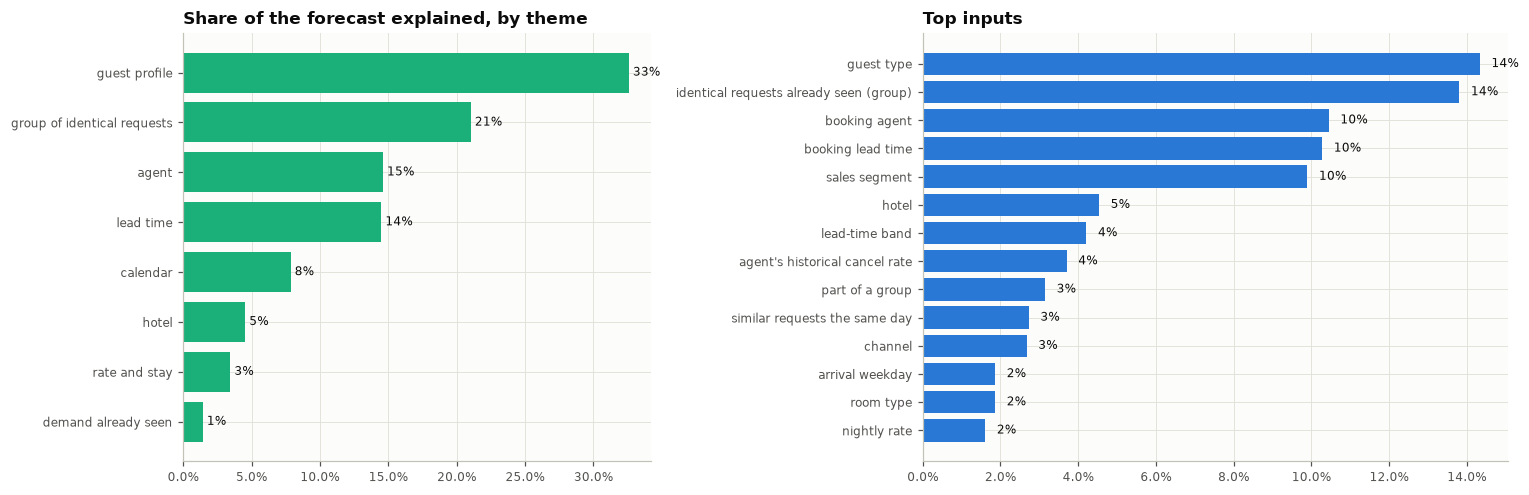

In [2]:
imp = pd.read_csv(R / "06_feature_importance.csv")
th = imp.groupby("theme").share.sum().sort_values()
top = imp.groupby("label").share.sum().sort_values().tail(14)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1, 1.25]})
axes[0].barh(th.index, th, color=P.OURS)
axes[1].barh(top.index, top, color=P.BLUE)
for ax, v in ((axes[0], th), (axes[1], top)):
    for i, x in enumerate(v):
        ax.text(x + .003, i, f"{x:.0%}", va="center", fontsize=8)
    ax.xaxis.set_major_formatter(P.PCT)
axes[0].set_title("Share of the forecast explained, by theme")
axes[1].set_title("Top inputs")
P.save(fig, "importance")
plt.tight_layout(); plt.show()

Three themes explain two thirds of the forecast: **the guest profile** (guest type, sales
segment, channel, room and party: 33%), **group membership** observed live (21%) and **the
agency** with its track record (15%). Lead time follows (14%). The rate itself and the stay
length matter little for the *cancellation* forecast (3%): price enters the decision through the
bid price, not through the probability. The single most used input is the guest type, followed
by the count of identical requests already seen and the agent.

## 2 · What each member contributes

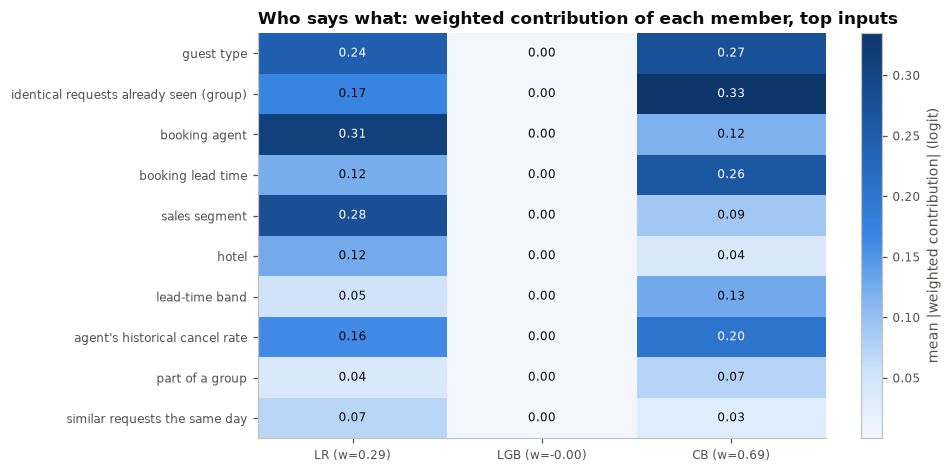

In [3]:
mem = pd.read_csv(R / "06_member_importance.csv")
cols = imp.groupby("label").share.sum().sort_values(ascending=False).head(10).index
t = mem.groupby(["label", "member"]).mean_abs_weighted.sum().unstack().reindex(cols)[["lr", "lgb", "cb"]]
t.columns = [f"{c.upper()} (w={add['stack_weights'][c]:.2f})" for c in t.columns]
fig, ax = plt.subplots(figsize=(9, 4.4))
im = ax.imshow(t.values, cmap=P.BLUES, aspect="auto")
ax.set_xticks(range(t.shape[1]), t.columns); ax.set_yticks(range(len(t)), t.index); ax.grid(False)
for (r, c_), v in np.ndenumerate(t.values):
    ax.text(c_, r, f"{v:.2f}", ha="center", va="center", fontsize=8, color="white" if v > t.values.max() * .55 else P.INK)
fig.colorbar(im, ax=ax, label="mean |weighted contribution| (logit)")
ax.set_title("Who says what: weighted contribution of each member, top inputs")
plt.tight_layout(); plt.show()

CatBoost carries most of the weight (0.69) and contributes most on guest type, the agent's
historical cancel rate and group membership; logistic regression (weight 0.29) contributes mainly
through the agent, the sales segment and guest type. LightGBM's weight is essentially zero in this
final fit (−0.002): it adds nothing once the other two are present (its weight ranges from 0.07 to
0.33 across the validation cuts, notebook 07).

## 3 · The deliverable, explaining itself

`Solution` is the class handed to the organisers. After every `decide()`, `explain()` returns the
reason in plain English. Here it runs on the second half of 2016. The shipped model was trained on
all of 2015–2016, so these requests are in-sample: the point is to show the explanations, not to
measure performance (that was done out of time in notebooks 07–08).

In [4]:
from solution import Solution

df = load_train()
ho = build_holdout(df, start="2016-07-01")
sol = Solution(ho.commitments.copy(), {h: c.copy() for h, c in ho.capacity.items()})
log, arrays = [], {}
for b in ho.requests.head(3000).to_dict("records"):
    ok = sol.decide(b)
    kind = outcome(sol.policy.last, ok)
    log.append({"booking_id": b["booking_id"], "hotel": b["hotel"], "rate": b["nightly_rate"], "nights": b["nights"],
                "outcome": kind, "p_cancel": sol.policy.last.get("p_cancel"), "bid": sol.policy.last.get("bid"),
                "reason": sol.explain()})
    if kind != "invalid":
        arrays[b["booking_id"]] = sol.model.last_array.copy()
log = pd.DataFrame(log)
examples = pd.concat([log[log.outcome == k].sample(2, random_state=3) for k in ["accepted", "price", "full"]])
for r in examples.itertuples():
    print(f"[{r.outcome}] {r.reason}\n")

[accepted] accepted: Downtown Hotel, 1 nights at 90 EUR: show-up probability 0.34, expected value 30 EUR; rate 90 EUR >= reserve price 0 EUR and the expected guests fit the free rooms; main factors: guest type (more cancellation), sales segment (less cancellation), booking lead time (more cancellation)

[accepted] accepted: Downtown Hotel, 11 nights at 118 EUR: show-up probability 0.22, expected value 282 EUR; rate 118 EUR >= reserve price 89 EUR and the expected guests fit the free rooms; main factors: guest type (more cancellation), requests already seen for the week (more cancellation), booking lead time (more cancellation)

[price] rejected: Downtown Hotel, 1 nights at 65 EUR: show-up probability 0.87, expected value 57 EUR; rate 65 EUR < reserve price 166 EUR (we still expect demand that pays more for these nights); main factors: booking lead time (less cancellation), company booking (less cancellation), guest type (more cancellation)

[price] rejected: Downtown Hotel, 2 nights at

Each reason states the probability, the expected value, the bid price of the nights, the check
that decided, and the three inputs that moved the cancellation forecast most. The same numbers
can be drawn as a waterfall: from the base rate to the final probability, input by input.

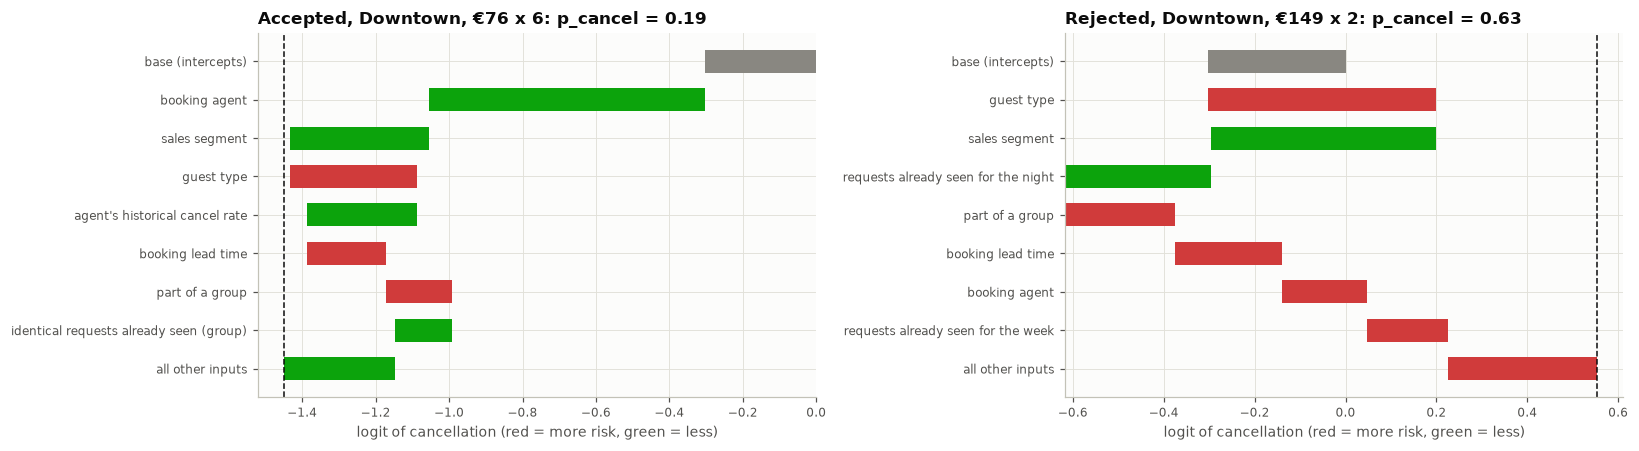

accepted: Downtown Hotel, 6 nights at 76 EUR: show-up probability 0.81, expected value 368 EUR; rate 76 EUR >= reserve price 65 EUR and the expected guests fit the free rooms; main factors: booking agent (less cancellation), sales segment (less cancellation), guest type (more cancellation) 

 rejected: Downtown Hotel, 2 nights at 149 EUR: show-up probability 0.37, expected value 109 EUR; rate 149 EUR < reserve price 157 EUR (we still expect demand that pays more for these nights); main factors: guest type (more cancellation), sales segment (less cancellation), requests already seen for the night (less cancellation)


In [5]:
def waterfall(ax, bid_id, title):
    contrib, const = decompose(sol.model, arrays[bid_id])
    s = pd.Series(contrib, index=[label(c) for c in sol.model.fb.columns_]).groupby(level=0).sum()
    s = s.reindex(s.abs().sort_values(ascending=False).index)
    shown, rest = s.head(7), s.iloc[7:].sum()
    steps = pd.concat([pd.Series({"base (intercepts)": const}), shown, pd.Series({"all other inputs": rest})])
    pos = np.concatenate([[0], np.cumsum(steps.values)[:-1]])
    colors = [P.MUTED] + [P.CRITICAL if v > 0 else P.GOOD for v in steps.values[1:]]
    ax.barh(range(len(steps)), steps.values, left=pos, color=colors, height=.6)
    z = steps.sum()
    ax.axvline(z, color=P.INK, lw=1, ls="--")
    ax.set_yticks(range(len(steps)), steps.index); ax.invert_yaxis()
    ax.set(title=f"{title}: p_cancel = {1 / (1 + np.exp(-z)):.2f}", xlabel="logit of cancellation (red = more risk, green = less)")


acc = log[(log.outcome == "accepted") & (log.p_cancel < .2)].iloc[0]
rej = log[(log.outcome == "price") & (log.p_cancel > .5)].iloc[0]
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
waterfall(axes[0], acc.booking_id, f"Accepted, {acc.hotel.split()[0]}, €{acc.rate:.0f} x {acc.nights}")
waterfall(axes[1], rej.booking_id, f"Rejected, {rej.hotel.split()[0]}, €{rej.rate:.0f} x {rej.nights}")
P.save(fig, "waterfall")
plt.tight_layout(); plt.show()
print(acc.reason, "\n\n", rej.reason)

## 4 · Which reasons come up most often?

Over the whole second half of 2016, with the out-of-time model of notebook 08: the input that moved
each forecast most.

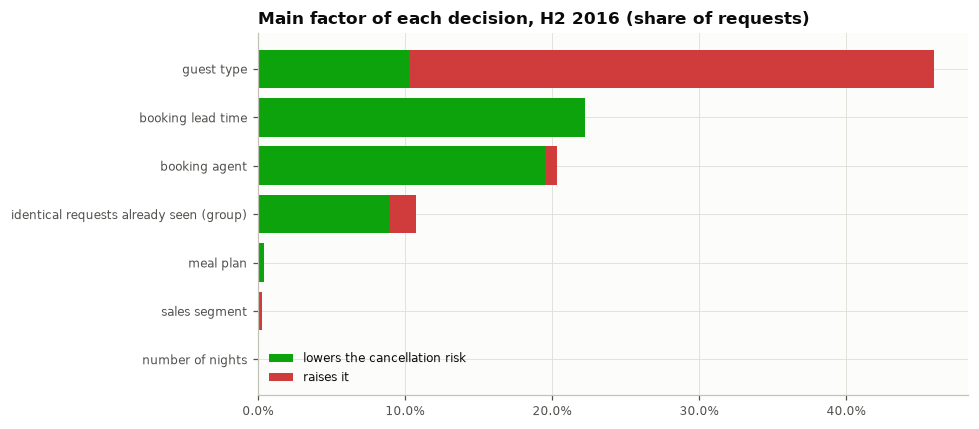

In [6]:
tr = pd.read_csv(R / "05_decisions_H2.csv")
tr = tr[tr.outcome != "invalid"]
t = (tr.assign(direction=np.where(tr.driver1_logit > 0, "raises risk", "lowers risk"))
       .groupby(["driver1", "direction"]).size().unstack().fillna(0))
t = t.loc[t.sum(axis=1).sort_values().index].tail(10) / len(tr)
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(t.index, t["lowers risk"], color=P.GOOD, label="lowers the cancellation risk")
ax.barh(t.index, t["raises risk"], left=t["lowers risk"], color=P.CRITICAL, label="raises it")
ax.xaxis.set_major_formatter(P.PCT); ax.legend()
ax.set_title("Main factor of each decision, H2 2016 (share of requests)")
plt.tight_layout(); plt.show()

**Guest type** is the main factor in almost half of the decisions, usually as a risk-raiser
(transient bookings cancel more). **The agent** and **the lead time** are the main factor in
about a fifth of the decisions each, almost always as risk-reducers (a reliable agency, a booking
made close to arrival). Group membership leads in about 11% of cases.

One caveat appears in the waterfalls: correlated inputs can carry contributions of opposite sign
(guest type up, sales segment down for the same booking). The model is right to split the credit
that way, but for a human reader the pair should be read together.

## Limits of the explanations

* TreeSHAP attributions are **exact for the model but not causal**: "guest type raised the risk"
  means the model used it, not that changing the guest type would change the guest's behaviour.
* CatBoost carries a large share of the weight in the final stack and is not readable on its own;
  its part of the explanation rests on SHAP. Logistic regression is readable directly.
* The stack weights move between validation cuts (notebook 07), so member-level stories should not
  be over-interpreted; the per-input total is the stable object.
* Correlated inputs (guest type and sales segment, agent and its historical rate) can show
  offsetting contributions; the explanation lists the top three, which should be read together.
* The personas of notebooks 04–05 are not inputs of the model; they are a vocabulary for
  describing customers, not part of the decision.